# 22. Composição das chaves exclusivas

O pareamento por logradouro e número deixa três grupos de chaves distintas: as que existem nas duas bases, as que só o CNEFE tem e as que só o BHMap tem. Este notebook mede o tamanho de cada grupo com o denominador explícito e procura, para cada chave exclusiva, a explicação que os dados sustentam. Ele responde a quatro perguntas.

1. Quanto cada grupo representa em registros e em chaves, e em relação a quê?
2. Algum tratamento de dado faria parte das chaves exclusivas encontrar par?
3. Que explicação os dados sustentam para cada chave exclusiva: outro número no mesmo lote, número ausente num logradouro conhecido ou logradouro ausente? E, do lado do BHMap, quantas chaves exclusivas aparecem só em pontos ainda não vistoriados?
4. Quantos registros pareados têm mais de uma coordenada candidata, e como a distribuição muda quando cada chave tem o mesmo peso?

O cadastro imobiliário (IPTU) entra como testemunha da chave, e não como verdade de campo. A coordenada só serve para associar pontos a lotes e a vilas, nunca para formar pares. As entradas são as bases processadas do [NB01](01_ingestao.ipynb), o pareamento do [NB02](02_matching.ipynb) e o IPTU. Este é o último notebook da sequência analítica. A prova de conceito da API está no [NB14](14_api_poc.ipynb) e o teste independente da calibração no [NB17](17_teste_operacional_independente.ipynb).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/config.py').exists())
sys.path.insert(0, str(ROOT))
from src import config
from src.metrics import chave_identidade, separar_logradouro_numero, conciliar_logradouros
P = config.PROCESSED_DIR
OUT = config.OUTPUT_DIR
(OUT/'tables').mkdir(parents=True, exist_ok=True)
(OUT/'figures').mkdir(parents=True, exist_ok=True)
FIGD = config.FIG_DIR
FIGD.mkdir(parents=True, exist_ok=True)

cnefe = gpd.read_parquet(P/'cnefe_bh.parquet', columns=['LOGRAD_NUM', 'geometry'])
bh_total = gpd.read_parquet(P/'bhmap_bh.parquet', columns=['SIGLA_TIPO', 'NOME_LOGRA', 'NUMERO_IMO', 'EXISTENCIA', 'geometry'])
bh = bh_total
assert len(bh) == 757113
iptu = pd.read_csv(config.RAW_DIR/'bhmap_context'/'CADASTRO_IMOBILIARIO.csv',
                   usecols=['NULOTCTM', 'TIPO_LOGRADOURO', 'NOME_LOGRADOURO', 'NUMERO_IMOVEL'], dtype=str)
lotes = gpd.read_parquet(P/'lote_ctm.parquet', columns=['NULOTCTM', 'geometry']).drop_duplicates('NULOTCTM')
vilas = gpd.read_parquet(P/'vila_favela.parquet', columns=['geometry'])
assert lotes.crs == cnefe.crs == bh.crs == vilas.crs

def chave(log, num):
    return (log.astype('string')+'|'+num.astype('string')).where(log.notna() & log.ne('') & num.notna())

log_c, num_c = chave_identidade(*separar_logradouro_numero(cnefe.LOGRAD_NUM))
log_c.index = num_c.index = cnefe.index
def chaves_bhmap(df, tipos=None):
    tipo = df.SIGLA_TIPO.fillna('')
    if tipos: tipo = tipo.replace(tipos)
    l, n = chave_identidade(tipo+' '+df.NOME_LOGRA.fillna(''), df.NUMERO_IMO)
    l.index = n.index = df.index
    return l, n
log_b, num_b = chaves_bhmap(bh)
mapa_c = conciliar_logradouros(log_c.unique(), log_b.unique(), limiar=90, margem=2)
log_cc = log_c.map(lambda v: mapa_c.get(v, v))
kc, kb = chave(log_cc, num_c), chave(log_b, num_b)
tipo_i = iptu.TIPO_LOGRADOURO.fillna('').str.replace(r'^BEC$', 'BECO', regex=True)
log_i, num_i = chave_identidade(tipo_i+' '+iptu.NOME_LOGRADOURO.fillna(''), iptu.NUMERO_IMOVEL)
mapa_i = conciliar_logradouros(log_i.unique(), log_b.unique(), limiar=90, margem=2)
ki = chave(log_i.map(lambda v: mapa_i.get(v, v)), num_i)
SC, SB, SI = set(kc.dropna()), set(kb.dropna()), set(ki.dropna())
so_c, so_b, comum = SC-SB, SB-SC, SC & SB
assert (len(SC), len(SB), len(comum), len(so_c), len(so_b)) == (456022, 613763, 404796, 51226, 208967)
print('chaves CNEFE', len(SC), 'BHMap', len(SB), 'comuns', len(comum), 'so CNEFE', len(so_c), 'so BHMap', len(so_b))

chaves CNEFE 456022 BHMap 613763 comuns 404796 so CNEFE 51226 so BHMap 208967


A referência são todos os 757.113 pontos do BHMap. A reconstrução reproduz os conjuntos do pareamento: 456.022 chaves no CNEFE, 613.763 no BHMap, 404.796 comuns, 51.226 só no CNEFE e 208.967 só no BHMap.

## 1. Registros e chaves, com os denominadores explícitos

Um registro é uma linha da base: um endereço do CNEFE ou um ponto do BHMap. Uma chave é um par distinto de logradouro canônico e número. O CNEFE repete a mesma chave em vários registros, porque cada apartamento, sala ou loja de um edifício é um endereço próprio com o mesmo número de porta. Por isso os percentuais em registros e em chaves não coincidem, e cada um responde a uma pergunta diferente. Em registros, a pergunta é quantos endereços do Censo encontram correspondência. Em chaves, é quanto as duas bases compartilham como lista de endereços de porta.

In [2]:
reg = pd.DataFrame({
    'grupo': ['pareado (chave nas duas bases)', 'chave ausente do BHMap', 'sem numero (SN)'],
    'registros': [int(kc.isin(comum).sum()), int(kc.isin(so_c).sum()), int(kc.isna().sum())]})
reg['pct_registros_cnefe'] = 100*reg.registros/len(cnefe)
assert reg.registros.tolist() == [1062044, 95706, 22352] and reg.registros.sum() == len(cnefe)
assert cnefe.LOGRAD_NUM[kc.isna()].str.strip().str.endswith(', SN').all()
pts_b = pd.DataFrame({'grupo': ['chave presente no CNEFE', 'chave ausente do CNEFE', 'sem chave valida'],
                      'pontos': [int(kb.isin(comum).sum()), int(kb.isin(so_b).sum()), int(kb.isna().sum())]})
pts_b['pct_pontos_bhmap'] = 100*pts_b.pontos/len(bh)
uniao = SC | SB
ch = pd.DataFrame({'grupo': ['comuns', 'so CNEFE', 'so BHMap'],
                   'chaves': [len(comum), len(so_c), len(so_b)]})
ch['pct_chaves_cnefe'] = [100*len(comum)/len(SC), 100*len(so_c)/len(SC), np.nan]
ch['pct_chaves_bhmap'] = [100*len(comum)/len(SB), np.nan, 100*len(so_b)/len(SB)]
ch['pct_uniao'] = 100*ch.chaves/len(uniao)
reg_por_chave = kc.dropna().value_counts()
dens = pd.Series({'registros por chave comum': reg_por_chave[list(comum)].mean(),
                  'registros por chave so CNEFE': reg_por_chave[list(so_c)].mean()})
reg.to_csv(OUT/'tables/nb22_registros_cnefe.csv', index=False)
pts_b.to_csv(OUT/'tables/nb22_pontos_bhmap.csv', index=False)
ch.to_csv(OUT/'tables/nb22_chaves.csv', index=False)
print(reg.round(1).to_string(index=False)); print(pts_b.round(1).to_string(index=False))
print(ch.round(1).to_string(index=False)); print('uniao', len(uniao)); print(dens.round(2).to_string())

                         grupo  registros  pct_registros_cnefe
pareado (chave nas duas bases)    1062044                 90.0
        chave ausente do BHMap      95706                  8.1
               sem numero (SN)      22352                  1.9
                  grupo  pontos  pct_pontos_bhmap
chave presente no CNEFE  530681              70.1
 chave ausente do CNEFE  226432              29.9
       sem chave valida       0               0.0
   grupo  chaves  pct_chaves_cnefe  pct_chaves_bhmap  pct_uniao
  comuns  404796              88.8              66.0       60.9
so CNEFE   51226              11.2               NaN        7.7
so BHMap  208967               NaN              34.0       31.4
uniao 664989
registros por chave comum       2.62
registros por chave so CNEFE    1.87


Em registros, 90,0% dos 1.180.102 registros do CNEFE têm par, 8,1% têm chave ausente do BHMap e 1,9% não têm número. Do lado do BHMap, 70,1% dos pontos têm chave presente no CNEFE. Em chaves, as 404.796 comuns são 88,8% das chaves do CNEFE, 66,0% das do BHMap e 60,9% da união. Cada chave comum reúne, em média, 2,62 registros do CNEFE, e cada chave exclusiva 1,87. É por isso que a cobertura se informa em registros e a sobreposição em chaves.

## 2. Há tratamento de dado que faria as exclusivas casarem?

O dicionário de tipos de logradouro expande RUA, AVE, ALA, PCA, TRV, ROD, EST e VIA, mas não BEC, VDT, LRG e TRE, que o BHMap usa para beco, viaduto, largo e trevo. A conciliação de grafia já aproxima boa parte desses casos, porque "BECO X" e "BEC X" passam do limiar de similaridade. Medimos o efeito de acrescentar os quatro códigos e o comparamos às outras duas regras de chave já relatadas, a exata e a que preserva sufixo de número. Os códigos VDP, RDP, TRI e ELP, com 644 pontos, não têm significado documentado e ficam como estão.

In [3]:
def conjuntos(log_cnefe, num_cnefe, log_bh, num_bh, conciliar=True):
    if conciliar:
        m = conciliar_logradouros(log_cnefe.unique(), log_bh.unique(), limiar=90, margem=2)
        log_cnefe = log_cnefe.map(lambda v: m.get(v, v))
    a, b = chave(log_cnefe, num_cnefe), chave(log_bh, num_bh)
    A, D = set(a.dropna()), set(b.dropna())
    return {'comuns': len(A & D), 'so_cnefe': len(A-D), 'so_bhmap': len(D-A), 'registros_pareados': int(a.isin(A & D).sum())}
def numero_com_sufixo(serie):
    texto = serie.astype('string').str.upper().str.strip().str.replace(r'^(\d+)\.0$', r'\1', regex=True)
    partes = texto.str.extract(r'^0*(\d+)\s*([A-Z]?)$')
    return partes[0].str.lstrip('0').replace('', pd.NA)+partes[1].fillna('')
lc_bruto, nc_bruto = separar_logradouro_numero(cnefe.LOGRAD_NUM)
lb_tipos, nb_tipos = chaves_bhmap(bh, {'BEC': 'BECO', 'VDT': 'VIADUTO', 'LRG': 'LARGO', 'TRE': 'TREVO'})
nc_suf, nb_suf = numero_com_sufixo(nc_bruto), numero_com_sufixo(bh.NUMERO_IMO)
nc_suf.index = cnefe.index; nb_suf.index = bh.index
sens = pd.DataFrame([
    {'regra': 'exata', **conjuntos(log_c, num_c, log_b, num_b, conciliar=False)},
    {'regra': 'conciliada (adotada)', **conjuntos(log_c, num_c, log_b, num_b)},
    {'regra': 'conciliada + codigos de tipo', **conjuntos(log_c, num_c, lb_tipos, nb_tipos)},
    {'regra': 'conciliada + sufixo preservado', **conjuntos(log_c, nc_suf, log_b, nb_suf)}])
assert sens.loc[1, ['comuns', 'so_cnefe', 'so_bhmap', 'registros_pareados']].tolist() == [404796, 51226, 208967, 1062044]
sens['delta_registros'] = sens.registros_pareados-1062044
sens.to_csv(OUT/'tables/nb22_sensibilidade_tratamento.csv', index=False)
print(bh.SIGLA_TIPO.value_counts().loc[lambda s: ~s.index.isin(['RUA','AVE','ALA','PCA','TRV','ROD','EST','VIA'])].to_string())
print(sens.to_string(index=False))

SIGLA_TIPO
BEC    34371
VDP      616
TRE       41
LRG       17
RDP       13
VDT       12
ELP        9
TRI        6
ACS        2
TUN        1
                         regra  comuns  so_cnefe  so_bhmap  registros_pareados  delta_registros
                         exata  386545     69622    227218             1025630           -36414
          conciliada (adotada)  404796     51226    208967             1062044                0
  conciliada + codigos de tipo  404903     51068    208860             1062277              233
conciliada + sufixo preservado  390359    161763    223404              919633          -142411


Os quatro códigos ausentes do dicionário somam 34.441 pontos, quase todos BEC (34.371). Acrescentá-los leva 107 chaves à interseção e 233 registros ao pareamento, porque a conciliação de grafia já aproximava BECO de BEC. A regra exata deixa de parear 36.414 registros, e preservar o sufixo deixa de parear 142.411, porque separa chaves que a regra principal junta. A chave conciliada fica como está, e a diferença que sobra entre as bases não vem da normalização.

## 3. De onde vêm as chaves exclusivas

Classificamos cada chave exclusiva pela primeira explicação que os dados sustentam, nesta ordem:

1. **Outro número no mesmo lote.** Algum registro da chave fica a até 10 m de um lote fiscal que também recebe, a até 10 m, um ponto da outra base no mesmo logradouro com número diferente. É o caso típico de esquina, imóvel com mais de uma entrada ou numeração revista.
2. **Logradouro presente, número ausente.** O logradouro existe na outra base, mas aquele número não.
3. **Logradouro ausente.** O nome não existe na outra base, nem depois da conciliação de grafia. Inclui ruas renomeadas, vias sem denominação oficial e grafias distantes demais para a conciliação.

Em cada classe medimos a parcela confirmada pelo IPTU e a parcela em vilas e favelas mapeadas.

In [4]:
def lote_proximo(pts):
    j = gpd.sjoin_nearest(pts[['geometry']], lotes, how='left', max_distance=10)
    return j[~j.index.duplicated()].NULOTCTM
em_vila_c = cnefe.index.isin(gpd.sjoin(cnefe[['geometry']], vilas, predicate='within').index)
em_vila_b = bh.index.isin(gpd.sjoin(bh[['geometry']], vilas, predicate='within').index)
assert em_vila_c.sum() == 128149
lote_b = lote_proximo(bh)
m_cx = kc.isin(so_c)
lote_cx = lote_proximo(cnefe[m_cx])
m_bx = kb.isin(so_b)
lote_c = lote_proximo(cnefe[kc.notna()])

def mesmo_lote_outro_numero(lote_alvo, log_alvo, num_alvo, lote_outro, log_outro, num_outro, chave_alvo):
    a = pd.DataFrame({'lote': lote_alvo, 'log': log_alvo.reindex(lote_alvo.index), 'num': num_alvo.reindex(lote_alvo.index),
                      'chave': chave_alvo.reindex(lote_alvo.index)}).dropna()
    o = pd.DataFrame({'lote': lote_outro, 'log': log_outro.reindex(lote_outro.index), 'num_o': num_outro.reindex(lote_outro.index)}).dropna()
    o = o.drop_duplicates()
    j = a.merge(o, on=['lote', 'log'])
    j = j[j.num.ne(j.num_o)]
    return set(j.chave)

def classificar(exclusivas, chaves_alvo, log_alvo, logs_outro, mesmo_lote, filtro=None):
    rot = pd.Series('logradouro ausente', index=sorted(exclusivas))
    log_da_chave = pd.Series({k: k.split('|')[0] for k in rot.index})
    rot[log_da_chave.isin(logs_outro)] = 'logradouro presente, numero ausente'
    rot[rot.index.isin(list(mesmo_lote))] = 'outro numero no mesmo lote'
    if filtro is not None: rot[rot.index.isin(list(filtro))] = 'filtro de existencia'
    return rot

lote_mc = mesmo_lote_outro_numero(lote_cx, log_cc, num_c, lote_b, log_b, num_b, kc)
classe_c = classificar(so_c, kc, log_cc, set(log_b.dropna()), lote_mc)
lote_mb = mesmo_lote_outro_numero(lote_proximo(bh[m_bx]), log_b, num_b, lote_c, log_cc, num_c, kb)
classe_b = classificar(so_b, kb, log_b, set(log_cc.dropna()), lote_mb)

def resumo(classe, chaves_reg, em_vila, nome):
    reg = pd.DataFrame({'chave': chaves_reg, 'vila': em_vila})
    reg = reg[reg.chave.isin(classe.index)]
    reg['classe'] = reg.chave.map(classe)
    vila_chave = reg.groupby('chave').vila.any()
    t = pd.DataFrame({'classe': classe, 'iptu': classe.index.isin(list(SI)), 'vila': vila_chave.reindex(classe.index).to_numpy()})
    r = t.groupby('classe').agg(chaves=('iptu', 'size'), iptu=('iptu', 'sum'), chaves_em_vila=('vila', 'sum'))
    r['registros'] = reg.groupby('classe').size()
    r['registros_em_vila'] = reg.groupby('classe').vila.sum()
    r['pct_registros_em_vila'] = 100*r.registros_em_vila/r.registros
    r['pct_exclusivas'] = 100*r.chaves/len(classe)
    r['pct_iptu'] = 100*r.iptu/r.chaves
    r['pct_em_vila'] = 100*r.chaves_em_vila/r.chaves
    r.insert(0, 'base', nome)
    return r.reset_index()
ordem = ['outro numero no mesmo lote', 'logradouro presente, numero ausente', 'logradouro ausente']
comp = pd.concat([resumo(classe_c, kc, em_vila_c, 'so CNEFE'), resumo(classe_b, kb, em_vila_b, 'so BHMap')])
comp['ordem'] = comp.classe.map(ordem.index)
comp = comp.sort_values(['base', 'ordem'], ascending=[False, True]).drop(columns='ordem')
assert comp.query('base=="so CNEFE"').chaves.sum() == 51226 and comp.query('base=="so CNEFE"').registros.sum() == 95706
assert comp.query('base=="so BHMap"').chaves.sum() == 208967
assert comp.query('base=="so CNEFE"').iptu.sum() == 1171 and comp.query('base=="so BHMap"').iptu.sum() == 48341
comp.to_csv(OUT/'tables/nb22_composicao_exclusivas.csv', index=False)
print(comp.round(1).to_string(index=False))

                             classe     base  chaves  iptu  chaves_em_vila  registros  registros_em_vila  pct_registros_em_vila  pct_exclusivas  pct_iptu  pct_em_vila
         outro numero no mesmo lote so CNEFE   18802   665            6014      34224               9288                   27.1            36.7       3.5         32.0
logradouro presente, numero ausente so CNEFE   15931   202            6502      28285              10123                   35.8            31.1       1.3         40.8
                 logradouro ausente so CNEFE   16493   304            6893      33197              11022                   33.2            32.2       1.8         41.8
         outro numero no mesmo lote so BHMap  113372 23713           22046     121427              24414                   20.1            54.3      20.9         19.4
logradouro presente, numero ausente so BHMap   70389 20167           12597      75854              14039                   18.5            33.7      28.7         17.

As 51.226 chaves só do CNEFE dividem-se em três grupos de tamanho parecido: outro número no mesmo lote (36,7%), logradouro presente sem aquele número (31,1%) e logradouro ausente (32,2%). Esses grupos quase nunca estão no IPTU (de 1,3% a 3,5%), e cerca de um terço dos seus registros fica em vilas e favelas, que reúnem 10,9% da base.

Do lado do BHMap, 54,3% das 208.967 chaves exclusivas têm, no mesmo lote, um registro do CNEFE no mesmo logradouro com outro número, o que é compatível com esquinas, imóveis de várias entradas ou numeração diferente. Outras 33,7% são números ausentes de logradouros que o CNEFE conhece, e 12,1% são logradouros ausentes, quase metade deles com ponto em vila ou favela. O IPTU reconhece 23,1% dessas chaves.

## 4. O que a vistoria do CTM qualifica

A placa do número (`EXISTENCIA`) não retira pontos da referência, mas qualifica o conjunto só do BHMap. Segundo o manual da Prodabel, o ponto a confirmar é um número concedido que a equipe do CTM ainda não vistoriou. Separamos as chaves só do BHMap que aparecem apenas em pontos a confirmar das que têm algum ponto vistoriado, com ou sem placa, e cruzamos as primeiras com as classes da Seção 3. Também medimos quantos registros só do CNEFE têm apoio fiscal, isto é, estão a até 10 m de um lote ao qual o IPTU associa a mesma chave.

In [5]:
vistoria_k = pd.DataFrame({'k': kb, 'ex': bh.EXISTENCIA}).dropna(subset=['k']).groupby('k').ex.agg(
    lambda s: 'Sim' if s.eq('Sim').any() else ('Não' if s.eq('Não').any() else 'a confimar'))
vistoria_b = vistoria_k.reindex(classe_b.index).eq('a confimar').map({True: 'só pontos a confirmar', False: 'algum ponto vistoriado'})
tab_vistoria = pd.crosstab(classe_b, vistoria_b, margins=True, margins_name='total')
assert tab_vistoria.loc['total', 'só pontos a confirmar'] == 53673 and tab_vistoria.loc['total', 'algum ponto vistoriado'] == 155294
I = pd.read_parquet(P/'cnefe_identidade.parquet')
assert int(I.pareado_identidade.sum()) == 1062044
alvo = kc.isin(so_c)
A = pd.DataFrame({'idx': cnefe.index[alvo], 'chave': kc[alvo].to_numpy(), 'xc': cnefe.geometry.x[alvo].to_numpy(), 'yc': cnefe.geometry.y[alvo].to_numpy()})
kl = pd.DataFrame({'chave': ki, 'NULOTCTM': iptu.NULOTCTM}).dropna().drop_duplicates()
lg = lotes.set_index('NULOTCTM').geometry
L = A.merge(kl, on='chave')
L['d'] = gpd.GeoSeries(gpd.points_from_xy(L.xc, L.yc), crs=cnefe.crs).distance(gpd.GeoSeries(lg.reindex(L.NULOTCTM).to_numpy(), crs=cnefe.crs)).to_numpy()
apoio = L.groupby('idx').d.min().le(10).reindex(A.idx, fill_value=False)
assert int(apoio.sum()) == 3082
apoio_tab = pd.Series({'registros_so_cnefe': len(A), 'com_apoio_fiscal_10m': int(apoio.sum()), 'pct': 100*apoio.mean()})
tab_vistoria.to_csv(OUT/'tables/nb22_so_bhmap_vistoria.csv')
apoio_tab.to_csv(OUT/'tables/nb22_apoio_fiscal_so_cnefe.csv', header=['valor'])
print(tab_vistoria.to_string()); print(apoio_tab.round(2).to_string())

ex                                   algum ponto vistoriado  só pontos a confirmar   total
row_0                                                                                     
logradouro ausente                                    20034                   5172   25206
logradouro presente, numero ausente                   51992                  18397   70389
outro numero no mesmo lote                            83268                  30104  113372
total                                                155294                  53673  208967
registros_so_cnefe      95706.00
com_apoio_fiscal_10m     3082.00
pct                         3.22


Das 208.967 chaves só do BHMap, 53.673 aparecem apenas em pontos a confirmar, números concedidos e nunca vistoriados, e 155.294 têm algum ponto vistoriado. A parcela com outro número do CNEFE no mesmo lote é parecida nos dois grupos, 56,1% e 53,6%. Do lado do CNEFE, só 3.082 dos 95.706 registros sem par (3,2%) têm apoio fiscal, porque os registros que o IPTU reconhecia passaram a encontrar par entre os pontos sem placa ou a confirmar.

## 5. Registros sem número

Os 22.352 registros do CNEFE sem chave são todos endereços "SN", sem número de porta. Não entram em nenhum dos conjuntos de chaves. Verificamos onde ficam e se o logradouro deles existe no BHMap.

In [6]:
sn = kc.isna()
r_sn = {'registros_sn': int(sn.sum()), 'pct_em_vila': 100*em_vila_c[sn].mean(),
        'pct_logradouro_no_bhmap': 100*log_cc[sn].isin(set(log_b.dropna())).mean(),
        'pct_vila_na_base': 100*em_vila_c.mean()}
seg = pd.DataFrame({'vila': em_vila_c, 'grupo': np.select([kc.isin(comum), kc.isin(so_c)], ['pareado', 'chave ausente do BHMap'], 'sem numero')})
tab_vila = pd.crosstab(seg.vila.map({True: 'em vila', False: 'fora'}), seg.grupo, normalize='index')*100
tab_vila.to_csv(OUT/'tables/nb22_grupos_por_vila.csv')
print(r_sn); print(tab_vila.round(1).to_string())

{'registros_sn': 22352, 'pct_em_vila': np.float64(22.467788117394417), 'pct_logradouro_no_bhmap': np.float64(87.705798138869), 'pct_vila_na_base': np.float64(10.859146073813958)}
grupo    chave ausente do BHMap  pareado  sem numero
vila                                                
em vila                    23.7     72.3         3.9
fora                        6.2     92.1         1.6


Os 22.352 registros sem número têm 22,5% em vilas e favelas, o dobro da participação desses territórios na base (10,9%), e 87,7% estão em logradouros que o BHMap conhece. O que lhes falta é o número da porta. Nas vilas, 3,9% dos registros não têm número, contra 1,6% fora delas.

## 6. Diagrama de Euler das chaves

Para dois conjuntos, o diagrama de Euler com áreas proporcionais mostra de uma vez quanto se sobrepõe e quanto sobra. A área de cada círculo é proporcional ao número de chaves distintas da base, e a distância entre os centros é calculada para que a interseção tenha exatamente a área das chaves comuns. Cada região traz a contagem e o percentual, com o denominador escrito. As explicações das chaves exclusivas ficam na tabela da Seção 3.

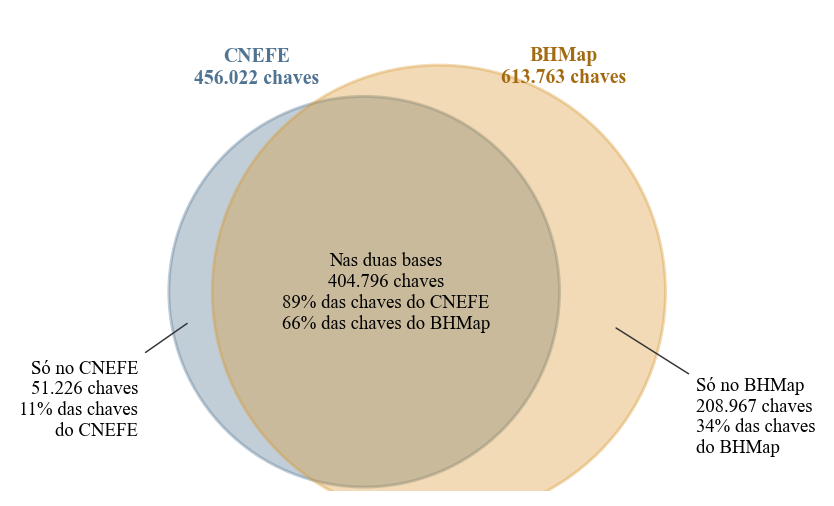

raios e distancia (unidades de area em chaves): [np.float64(381.0), np.float64(442.0), np.float64(145.7)]


In [7]:
from matplotlib.patches import Circle
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'], 'font.size': 8})
COR_C, COR_B = '#4f7391', '#d9962b'

def geometria_euler(a1, a2, a12):
    r1, r2 = np.sqrt(a1/np.pi), np.sqrt(a2/np.pi)
    def lente(d):
        x1 = np.clip((d*d+r1*r1-r2*r2)/(2*d*r1), -1, 1)
        x2 = np.clip((d*d+r2*r2-r1*r1)/(2*d*r2), -1, 1)
        q = max((-d+r1+r2)*(d+r1-r2)*(d-r1+r2)*(d+r1+r2), 0)
        return r1*r1*np.arccos(x1)+r2*r2*np.arccos(x2)-.5*np.sqrt(q)
    lo, hi = abs(r1-r2)+1e-9, r1+r2
    for _ in range(200):
        m = (lo+hi)/2
        lo, hi = (m, hi) if lente(m) > a12 else (lo, m)
    d = (lo+hi)/2
    assert abs(lente(d)-a12)/a12 < 1e-6
    return r1, r2, d

TXT = {
 'en': {'c': 'CNEFE\n{n} keys', 'b': 'BHMap\n{n} keys',
        'comum': 'In both\n{n} keys\n{pc:.0f}% of CNEFE keys\n{pb:.0f}% of BHMap keys',
        'so_c': 'Only in CNEFE\n{n} keys\n{p:.0f}% of CNEFE keys', 'so_b': 'Only in BHMap\n{n} keys\n{p:.0f}% of BHMap keys', 'sep': ','},
 'pt': {'c': 'CNEFE\n{n} chaves', 'b': 'BHMap\n{n} chaves',
        'comum': 'Nas duas bases\n{n} chaves\n{pc:.0f}% das chaves do CNEFE\n{pb:.0f}% das chaves do BHMap',
        'so_c': 'Só no CNEFE\n{n} chaves\n{p:.0f}% das chaves\ndo CNEFE', 'so_b': 'Só no BHMap\n{n} chaves\n{p:.0f}% das chaves\ndo BHMap', 'sep': '.'}}

def euler(lingua, destinos, compacto=False):
    t = TXT[lingua]
    fmt = lambda n: f'{n:,}'.replace(',', t['sep'])
    r1, r2, d = geometria_euler(len(SC), len(SB), len(comum))
    c1, c2 = (0, 0), (d, 0)
    fs = 9.5 if compacto else 9
    fig, ax = plt.subplots(figsize=(3.9, 2.3) if compacto else (6.6, 3.2))
    for c, r, cor in [(c1, r1, COR_C), (c2, r2, COR_B)]:
        ax.add_patch(Circle(c, r, facecolor=cor, alpha=.35, edgecolor=cor, lw=1.4))
    x_lente = ((d-r2)+r1)/2
    ax.text(x_lente, 0, t['comum'].format(n=fmt(len(comum)), pc=100*len(comum)/len(SC), pb=100*len(comum)/len(SB)),
            ha='center', va='center', fontsize=fs)
    ax.text(-r1*.55, r1*1.04, t['c'].format(n=fmt(len(SC))), ha='center', va='bottom', fontsize=fs+.5, color=COR_C, fontweight='bold')
    ax.text(d+r2*.55, r2*1.04+(r1-r2), t['b'].format(n=fmt(len(SB))), ha='center', va='bottom', fontsize=fs+.5, color='#a36a12', fontweight='bold')
    xc = (-r1+(d-r2))/2
    xb = (r1+(d+r2))/2
    ax.annotate(t['so_c'].format(n=fmt(len(so_c)), p=100*len(so_c)/len(SC)), xy=(xc, -r1*.15), xytext=(-r1-60, -r1*.55),
                ha='right', va='center', fontsize=fs, arrowprops={'arrowstyle': '-', 'color': '#333', 'lw': .7})
    ax.annotate(t['so_b'].format(n=fmt(len(so_b)), p=100*len(so_b)/len(SB)), xy=(xb, -r2*.15), xytext=(d+r2+60, -r2*.55),
                ha='left', va='center', fontsize=fs, arrowprops={'arrowstyle': '-', 'color': '#333', 'lw': .7})
    m = 330 if compacto else 300
    ax.set(xlim=(-r1-m, d+r2+m), ylim=(-r1*1.02, r1*(1.36 if compacto else 1.42)), aspect='equal'); ax.axis('off')
    fig.tight_layout(pad=.1)
    for f in destinos: fig.savefig(f, bbox_inches='tight', dpi=250)
    plt.show()
    return r1, r2, d

geo = euler('pt', [FIGD/'nb22_conjuntos_chaves.png'])
print('raios e distancia (unidades de area em chaves):', [round(v, 1) for v in geo])

O círculo do CNEFE fica quase todo dentro do círculo do BHMap, e a sobra do CNEFE é uma lua estreita, 11% das suas chaves. A do BHMap é maior, 34% das suas chaves. A figura deixa claro que nenhuma base contém a outra e que as duas compartilham a maior parte dos endereços de porta do CNEFE.

## 7. Candidatos múltiplos e agregação por chave

Duas verificações completam a descrição. A primeira conta quantos registros pareados têm, para a sua chave, mais de uma coordenada candidata no BHMap. Nesses casos, escolher a mais próxima minimiza a distância e torna a medida otimista. A segunda resume cada chave pela mediana das distâncias dos seus registros e calcula a mediana e o P90 dessas medianas. Cada chave passa a ter o mesmo peso, mas a variabilidade dentro dela também é resumida. A comparação não isola o efeito da repetição de registros nem demonstra que as distâncias por registro sejam conservadoras.

In [8]:
coord_b = pd.DataFrame({'chave': kb.to_numpy(), 'x': bh.geometry.x.round(2).to_numpy(), 'y': bh.geometry.y.round(2).to_numpy()}).dropna(subset=['chave'])
n_coord = coord_b.drop_duplicates().groupby('chave').size()
par = I.pareado_identidade.to_numpy()
kpar = kc[par]
multiplos = kpar.map(n_coord).gt(1)
assert len(kpar) == 1062044
d_reg = I.dist_identidade[par]
d_chave = pd.Series(d_reg.to_numpy(), index=kpar.to_numpy()).groupby(level=0).median()
rob = {'registros_pareados': len(kpar), 'registros_um_candidato': int((~multiplos).sum()), 'registros_multiplos_candidatos': int(multiplos.sum()),
       'mediana_registro_m': float(d_reg.median()), 'p90_registro_m': float(d_reg.quantile(.9)),
       'chaves_pareadas': len(d_chave), 'mediana_chave_m': float(d_chave.median()), 'p90_chave_m': float(d_chave.quantile(.9)),
       'acima_100m_chave_pct': float(100*d_chave.gt(100).mean())}
pd.Series(rob).to_csv(OUT/'tables/nb22_robustez_candidatos_ponderacao.csv')
print(json.dumps(rob, indent=1))

{
 "registros_pareados": 1062044,
 "registros_um_candidato": 818588,
 "registros_multiplos_candidatos": 243456,
 "mediana_registro_m": 9.837064278417728,
 "p90_registro_m": 35.58970751114782,
 "chaves_pareadas": 404796,
 "mediana_chave_m": 8.357574955639762,
 "p90_chave_m": 21.599788758160585,
 "acima_100m_chave_pct": 1.6729414322275913
}


Dos 1.062.044 registros pareados, 818.588 têm uma única coordenada candidata e 243.456 têm várias, casos em que escolher a mais próxima reduz a distância medida. Resumindo cada uma das 404.796 chaves pela mediana dos seus registros, a mediana entre chaves é de 8,4 m e o P90 de 21,6 m, contra 9,8 m e 35,6 m entre registros. A comparação muda os pesos e também resume a variação dentro de cada chave, e por isso descreve a distância típica de cada endereço de porta, sem isolar o efeito da repetição de registros.

O resumo abaixo grava os números principais em `nb22_resumo.json`.

In [9]:
resumo_json = {'registros': reg.set_index('grupo').registros.to_dict(), 'chaves': ch.set_index('grupo').chaves.to_dict(), 'uniao': len(uniao),
               'pct_comuns_cnefe': 100*len(comum)/len(SC), 'pct_comuns_bhmap': 100*len(comum)/len(SB),
               'iptu_comuns': len(comum & SI), 'iptu_so_cnefe': len(so_c & SI), 'iptu_so_bhmap': len(so_b & SI),
               'so_bhmap_so_a_confirmar': int(tab_vistoria.loc['total', 'só pontos a confirmar']), 'so_bhmap_vistoriadas': int(tab_vistoria.loc['total', 'algum ponto vistoriado']), 'so_cnefe_com_apoio_fiscal': int(apoio.sum()),
               'sn': r_sn, 'robustez': rob}
(OUT/'tables/nb22_resumo.json').write_text(json.dumps(resumo_json, ensure_ascii=False, indent=1, default=float), encoding='utf-8')
print(json.dumps(resumo_json, ensure_ascii=False, indent=1, default=float))

{
 "registros": {
  "pareado (chave nas duas bases)": 1062044,
  "chave ausente do BHMap": 95706,
  "sem numero (SN)": 22352
 },
 "chaves": {
  "comuns": 404796,
  "so CNEFE": 51226,
  "so BHMap": 208967
 },
 "uniao": 664989,
 "pct_comuns_cnefe": 88.76677002425322,
 "pct_comuns_bhmap": 65.95314478064009,
 "iptu_comuns": 271318,
 "iptu_so_cnefe": 1171,
 "iptu_so_bhmap": 48341,
 "so_bhmap_so_a_confirmar": 53673,
 "so_bhmap_vistoriadas": 155294,
 "so_cnefe_com_apoio_fiscal": 3082,
 "sn": {
  "registros_sn": 22352,
  "pct_em_vila": 22.467788117394417,
  "pct_logradouro_no_bhmap": 87.705798138869,
  "pct_vila_na_base": 10.859146073813958
 },
 "robustez": {
  "registros_pareados": 1062044,
  "registros_um_candidato": 818588,
  "registros_multiplos_candidatos": 243456,
  "mediana_registro_m": 9.837064278417728,
  "p90_registro_m": 35.58970751114782,
  "chaves_pareadas": 404796,
  "mediana_chave_m": 8.357574955639762,
  "p90_chave_m": 21.599788758160585,
  "acima_100m_chave_pct": 1.67294143222

## Conclusão

O CNEFE e o BHMap compartilham 404.796 chaves, 89% das chaves do CNEFE e dois terços das do BHMap, e 90,0% dos registros do Censo encontram par. Nenhum tratamento de normalização fecha a diferença que sobra. A expansão dos códigos de tipo de logradouro acrescenta só 233 registros.

As chaves que só o CNEFE tem quase nunca estão no IPTU e se concentram nas vilas e favelas. Do lado do BHMap, mais da metade das chaves exclusivas tem um registro do CNEFE no mesmo lote com outro número, e um quarto delas só aparece em pontos que o CTM ainda não vistoriou. As chaves exclusivas, nas duas bases, apontam para convenções de numeração e nomes de logradouro que uma base tem e a outra não, com peso maior nas vilas e favelas. Os registros sem número estão, na maioria, em logradouros conhecidos.

A ausência no BHMap não basta, portanto, para descartar um endereço do CNEFE. Para um repositório de referência, esses registros merecem permanecer com a proveniência explícita, e as chaves só em pontos a confirmar indicam onde a vistoria do cadastro municipal ainda não chegou.